# Shattering: fragments that arrive in a burst

### What you will learn

1. what shattering is, from a schematic of the probe's arm tips;
2. why the time between particles (the inter-arrival time) reveals it;
3. what the package's own shattering functions flag and re-accept on a synthetic stream;
4. how to look at the inter-arrival times in your own processed file;
5. what the package does by default.

### What data this uses

None from disk. The particle stream is **synthetic**, built here with a fixed seed
(`default_rng(14)`): ten seconds of natural particles plus bursts of fragments.

**Before this:** [05_triage_and_gallery](../1_getting_started/05_triage_and_gallery.ipynb) (Looking at particles: a contact sheet, a gallery, and the triage page), [12_particle_gallery](12_particle_gallery.ipynb) (What is not a particle: a gallery of optical array probe artifacts). **Related:** [09_shattering_interarrival_fit](09_shattering_interarrival_fit.ipynb). **Needs:** `pip install "arrayprobe[extra,zarr]"` (matplotlib, xarray).

This notebook reads files from the arrayprobe source repository, so run it from a clone of that repository; `pip install arrayprobe` alone does not include them.

The next cell checks that the notebook runs from the repository root, where the paths below start.

In [1]:
# Launch guard: the cells below reach scripts/ and tests/data/ relative to the repository root.
from pathlib import Path

if not (Path("scripts").is_dir() and Path("tests/data").is_dir()):
    raise RuntimeError(
        f"This notebook must run with the repository root as its working directory, not {Path.cwd()}. "
        "Jupyter starts a kernel in the notebook's own folder (examples/5_data_quality/), so run "
        "`%cd ../..` in a new cell, then run this cell again. "
        "Headless, from the repository root: python scripts/execute_example_notebooks.py --check <name>"
    )

import sys

if "examples" not in sys.path:  # shared helper modules (_style.py) sit in examples/
    sys.path.insert(0, "examples")

## 1. What shattering is

A large ice particle or drop that hits the probe's arm tips can break into many pieces. The pieces
cross the laser beam a few microseconds apart, so the probe records a burst of small "particles"
that were never in the air as separate particles. The schematic below shows the idea.

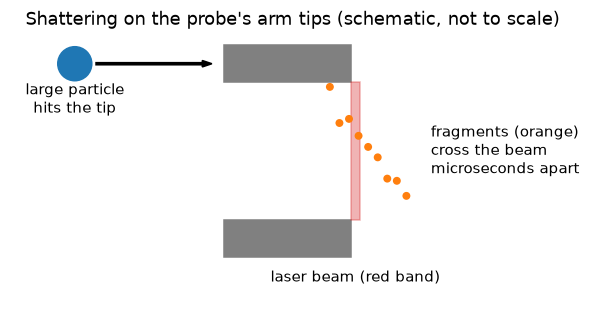

In [2]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Circle, FancyArrow

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.add_patch(Rectangle((0.0, 0.0), 1.2, 0.35, color="0.5"))   # lower arm tip
ax.add_patch(Rectangle((0.0, 1.65), 1.2, 0.35, color="0.5"))  # upper arm tip
ax.add_patch(Rectangle((1.2, 0.35), 0.08, 1.3, color="tab:red", alpha=0.35))
ax.text(1.24, -0.12, "laser beam (red band)", ha="center", va="top", fontsize=10)
ax.add_patch(Circle((-1.4, 1.82), 0.16, color="tab:blue"))
ax.add_patch(FancyArrow(-1.2, 1.82, 1.0, 0.0, width=0.02, color="k"))
ax.text(-1.4, 1.36, "large particle\nhits the tip", ha="center", fontsize=10)
rng = np.random.default_rng(3)
for k in range(9):
    ax.add_patch(Circle((1.0 + 0.09 * k, 1.5 - 0.11 * k + 0.05 * rng.standard_normal()),
                        0.03, color="tab:orange"))
ax.text(1.95, 1.0, "fragments (orange)\ncross the beam\nmicroseconds apart", va="center", fontsize=10)
ax.set_xlim(-2.0, 3.3); ax.set_ylim(-0.45, 2.1); ax.set_aspect("equal"); ax.axis("off")
ax.set_title("Shattering on the probe's arm tips (schematic, not to scale)")
plt.show()

*Figure 1. Schematic of shattering: a large particle (blue) strikes the upper arm tip and its fragments (orange) cross the laser beam (red band) between the two tips microseconds apart. Not to scale.*


The fragments look like real small particles in each image. What gives them away is *when* they
arrive, the subject of the next section.

## 2. Why inter-arrival times reveal it

Particles spread at random through the air arrive at the probe as a Poisson process. For a mean
rate $\lambda$ (particles per second) the time $\tau$ between one particle and the next follows
the exponential distribution

$$ p(\tau) = \lambda\, e^{-\lambda \tau}, \qquad \langle \tau \rangle = 1/\lambda . $$

At $\lambda = 200\ \mathrm{s^{-1}}$ the mean gap is 5 ms. Fragments of one burst arrive a few
microseconds apart, a thousand times sooner. We build both populations, with a label on every
particle so we can count what the package gets right.

In [3]:
rng = np.random.default_rng(14)
DUR, RATE = 10.0, 200.0          # seconds of flight, natural particles per second
EVENTS, FRAG_GAP = 20.0, 3e-6    # bursts per second, mean gap inside a burst (s)

t_nat = rng.uniform(0, DUR, rng.poisson(RATE * DUR))
bursts = []
for t0 in rng.uniform(0, DUR, rng.poisson(EVENTS * DUR)):
    n = rng.integers(3, 9)
    bursts.append(t0 + np.cumsum(np.r_[0.0, rng.exponential(FRAG_GAP, n - 1)]))
t_frag = np.concatenate(bursts)

t = np.r_[t_nat, t_frag]
is_frag = np.r_[np.zeros(t_nat.size, bool), np.ones(t_frag.size, bool)]
order = np.argsort(t, kind="stable")
t, is_frag = t[order], is_frag[order]
keep = t < DUR
t, is_frag = t[keep], is_frag[keep]
gap = np.diff(t, prepend=0.0)    # inter-arrival time before each particle (s)
print(f"{t.size} particles in {DUR:.0f} s: {(~is_frag).sum()} natural, {is_frag.sum()} fragments")

3203 particles in 10 s: 2049 natural, 1154 fragments


On logarithmic bins the inter-arrival histogram shows two modes: fragments near a few
microseconds and natural particles near $1/\lambda$. The dashed curve is the Poisson
prediction for the natural particles, $N\,\lambda\tau\,e^{-\lambda\tau}\,\Delta\ln\tau$ per bin
(the extra factor $\tau$ comes from using logarithmic bins).

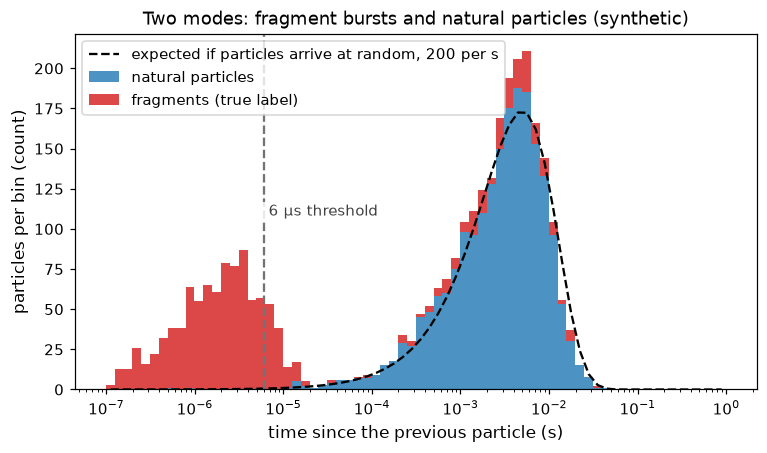

In [4]:
edges = np.logspace(-7, 0, 71)
mid = np.sqrt(edges[:-1] * edges[1:])
dln = np.log(edges[1] / edges[0])
h_all, _ = np.histogram(gap, edges)
h_frag, _ = np.histogram(gap[is_frag], edges)
poisson = (~is_frag).sum() * RATE * mid * np.exp(-RATE * mid) * dln

import _style                  # house style: _style.py sits beside this notebook
_style.apply()
fig, ax = plt.subplots(figsize=(8, 4.2))
_style.hist_stack(ax, edges, gap[~is_frag], gap[is_frag], kept_label="natural particles",
                  flag_label="fragments (true label)")
ax.plot(mid, poisson, "--", color=_style.TRUTH,
        label="expected if particles arrive at random, 200 per s")
_style.threshold_line(ax, 6e-6, "6 µs threshold")
ax.set_xlabel("time since the previous particle (s)")
ax.set_ylabel("particles per bin (count)")
ax.set_title("Two modes: fragment bursts and natural particles (synthetic)")
ax.legend(loc="upper left")
fig.savefig("examples/figures/shattering_modes.png", dpi=110, bbox_inches="tight")
plt.show()

The left mode is almost all fragments; the right mode follows the Poisson curve. A cutoff in the
empty valley between them separates the two.

## 3. How the package removes it

The UIOOPS engine's shattering step works one second at a time. Its flagging function,
`arrayprobe_uiops.sizedist_tables.flag_shattered_1hz` (`src/arrayprobe_uiops/sizedist_tables.py:563`,
a port of `sizeDist.m:1384-1396`), marks a particle `'S'` when its inter-arrival time is at or
below the threshold, and marks the particle just before it too. We run it with a 6 µs
threshold, the per-probe default the engine falls back to when no threshold file is given.

In [5]:
from arrayprobe_uiops.sizedist_tables import flag_shattered_1hz

THRESH = 6e-6                     # s
sec = np.floor(t).astype(int)
codes = np.empty(t.size, dtype="<U1")
for s in np.unique(sec):
    m = sec == s
    codes[m] = flag_shattered_1hz(gap[m].tolist(), THRESH)
flag = codes == "S"
print(f"flagged 'S': {flag.sum()} of {t.size} particles")
print(f"  fragments flagged:         {flag[is_frag].sum():5d} of {is_frag.sum()}"
      f" ({100 * flag[is_frag].mean():.2f} %)")
print(f"  natural particles flagged: {flag[~is_frag].sum():5d} of {(~is_frag).sum()}"
      f" ({100 * flag[~is_frag].mean():.2f} %)")

flagged 'S': 1087 of 3203 particles
  fragments flagged:          1081 of 1154 (93.67 %)
  natural particles flagged:     6 of 2049 (0.29 %)


Every number above is what the package's function returned on this stream. The figure below
draws the threshold on the histogram and splits each bin into what was flagged and what was kept.

flagged with own previous gap > threshold: 266
  true fragments (burst leaders): 263
  natural particles:              3
all natural particles flagged: 6


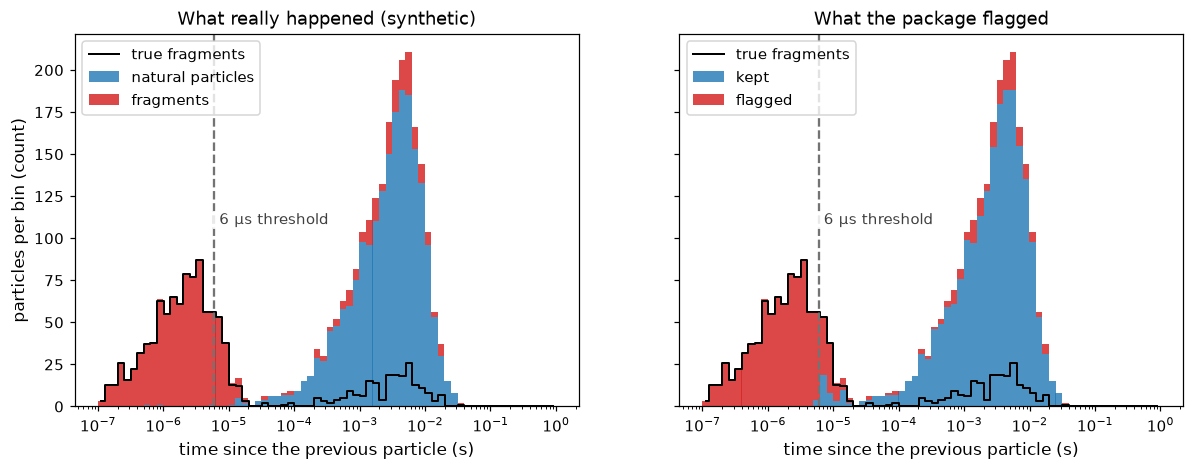

In [6]:
next_gap_all = np.r_[gap[1:], np.inf]
leader = flag & (gap > THRESH)        # flagged only through the NEXT particle's gap
lead_frag = leader & is_frag
print(f"flagged with own previous gap > threshold: {leader.sum()}")
print(f"  true fragments (burst leaders): {lead_frag.sum()}")
print(f"  natural particles:              {(leader & ~is_frag).sum()}")
print(f"all natural particles flagged: {(flag & ~is_frag).sum()}")

import _style
_style.apply()
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.4), sharey=True)
_style.hist_stack(a1, edges, gap[~is_frag], gap[is_frag], kept_label="natural particles",
                  flag_label="fragments", outline=gap[is_frag], outline_label="true fragments")
a1.set_title("What really happened (synthetic)")
_style.hist_stack(a2, edges, gap[~flag], gap[flag], kept_label="kept", flag_label="flagged",
                  outline=gap[is_frag], outline_label="true fragments")
a2.set_title("What the package flagged")
for a in (a1, a2):
    _style.threshold_line(a, THRESH, "6 µs threshold")
    a.legend(loc="upper left")
for a in (a1, a2):
    a.set_xlabel("time since the previous particle (s)")
a1.set_ylabel("particles per bin (count)")
a2.set_ylabel("")
fig.savefig("examples/figures/shattering_flagged.png", dpi=110, bbox_inches="tight")
plt.show()

Left: the labels. Right: the package's flag. Fragments (orange) appear in the natural mode
as well as at a few microseconds, and some of the right panel's red bars sit there too. The
histogram's x is each particle's gap to the *previous* particle, but `flag_shattered_1hz`
(`src/arrayprobe_uiops/sizedist_tables.py:563`, `sizeDist.m:1384-1396`) tests a particle's gap
to the previous one and also marks the one before it whenever the *next* gap is at or below the
threshold. The first fragment of each burst has a long gap before it (it arrives like any natural
particle, so it sits in the natural mode) and a tiny gap after it, so it is flagged. The counts
above separate these from natural particles. Fragments whose gaps exceed 6 µs survive.

### Re-acceptance of the large particle

The engine can also re-accept one particle per second: inside a run of flagged particles it
keeps the largest one above a size `reaccptD` whose gap is below `reaccptMaxIA`, marking it `'R'`
(`reaccept_shattered_1hz`, `src/arrayprobe_uiops/sizedist_tables.py:587`, a port of
`sizeDist.m:1398-1428`). The idea is that a burst may contain the original particle. The
sizes and the two settings below are for illustration only, not a shipped configuration.
The function does not test for `'S'` (faithful to `sizeDist.m:1398-1428`): it scans from the first to the
last burst in the second, so an unflagged particle in that span can be re-accepted. In the shipped presets
`reaccptMaxIA` (`sizeDist.m:192`, $10^{-6}$ s) lies below the flagging threshold, which confines the choice to
flagged particles.

In [7]:
from arrayprobe_uiops.sizedist_tables import reaccept_shattered_1hz

diam = np.where(is_frag, rng.uniform(25, 80, t.size), rng.uniform(25, 400, t.size))  # µm
next_gap = np.r_[gap[1:], 1.0]   # gap to the following particle (s)
n_r = 0
n_r_not_s = 0
for s in np.unique(sec):
    m = sec == s
    out, e_index = reaccept_shattered_1hz(
        codes[m].tolist(), gap[m].tolist(), next_gap[m].tolist(), diam[m].tolist(),
        THRESH, reaccptD=200.0, reaccptMaxIA=1e-6)   # um here; the shipped presets are 0.5 mm and 1e-6 s
    n_r += e_index is not None
    n_r_not_s += (e_index is not None) and codes[m][e_index - 1] != "S"
    codes[m] = out
print(f"seconds with a particle re-accepted ('R'): {n_r} of {np.unique(sec).size}")
print(f"re-accepted particles that had not been flagged 'S' first: {n_r_not_s}")
print(f"codes now: 'S' {np.sum(codes == 'S')}, 'R' {np.sum(codes == 'R')}")

seconds with a particle re-accepted ('R'): 2 of 10
re-accepted particles that had not been flagged 'S' first: 0
codes now: 'S' 1085, 'R' 2


In the v3.1.4 engine the same loop scans only the *first* burst in each second, a preserved
defect (`sizeDist.m:1036`, `:1169`); the v3.5 version ported here scans every burst.

### The measured quantities as a labelled dataset

The counts and gaps of this notebook, per population, in an `xarray.Dataset` with `units`
attributes.

In [8]:
import pandas as pd
import xarray as xr

pop = {"natural": ~is_frag, "fragment": is_frag}

def var(name, values, units):
    return xr.DataArray(values, dims="population", coords={"population": list(pop)},
                        attrs={"units": units}, name=name)

ds = xr.merge([
    var("particles", [int(m.sum()) for m in pop.values()], "count"),
    var("flagged_S", [int((flag & m).sum()) for m in pop.values()], "count"),
    var("median_gap", [float(np.median(gap[m])) for m in pop.values()], "s"),
])
ds.attrs["title"] = "Synthetic particle stream, shattering flags"
ds

<xarray.Dataset> Size: 112B
Dimensions:     (population: 2)
Coordinates:
  * population  (population) <U8 64B 'natural' 'fragment'
Data variables:
    particles   (population) int64 16B 2049 1154
    flagged_S   (population) int64 16B 6 1081
    median_gap  (population) float64 16B 0.003218 2.669e-06
Attributes:
    units:    count
    title:    Synthetic particle stream, shattering flags

The same numbers as a table, with the units in the column names and the flagged share added.

In [9]:
df = ds.to_dataframe()
df["flagged_share"] = 100 * df["flagged_S"] / df["particles"]
units = {**{v: ds[v].attrs["units"] for v in ds.data_vars}, "flagged_share": "%"}
df.columns = [f"{c} ({units[c]})" for c in df.columns]
df

,particles (count),flagged_S (count),median_gap (s),flagged_share (%)
population,,,,
natural,2049,6,0.003218,0.292826
fragment,1154,1081,0.000003,93.674177


The table repeats the section 3 counts, now with the median gap of each population.

## 4. How often

Skipping the shattering step altogether accepts particles the step would reject; how much this
mattered is not measured on data this package ships. A fraction of particles rejected over a set of flights is
**not measured yet**.

## 5. Check your own data

A processed (image-processing) file carries one inter-arrival time per particle in the variable
`inter_arrival` (units `sec`). The next cell plots its histogram on logarithmic bins once you set
`MY_FILE` to your own file; look for the two modes.

In [10]:
MY_FILE = None   # put the path to your own processed file here, e.g. "proc.base170707102822.H.nc"
if MY_FILE is None:
    print("Set MY_FILE above to one of your own files to run this cell.")
else:
    import arrayprobe
    ds = arrayprobe.open_product(MY_FILE)
    ia = ds["inter_arrival"].values
    ia = ia[ia > 0]
    plt.hist(ia, bins=np.logspace(-7, 0, 71)); plt.xscale("log")
    plt.xlabel("inter-arrival time (s)"); plt.ylabel("particles per bin (count)")

Set MY_FILE above to one of your own files to run this cell.


## 6. What the package does by default

The shattering step runs when a threshold is supplied (a threshold file, or the per-probe
default the engine falls back to); the call is recorded in the run's `.call` stamp, because the
output file alone cannot say whether it ran. Re-acceptance is a per-probe setting.

## What to try next

- Change `THRESH` to `2e-6` or `20e-6` and rerun section 3: watch the fragment and natural
  percentages trade against each other.
- Raise `RATE` to `2000`: the natural mode moves left toward the threshold and more natural
  particles are flagged.
- Raise `FRAG_GAP` to `1e-5`: bursts spread out and the fixed threshold misses more fragments.
- Next: [14_stray_pixels.ipynb](14_stray_pixels.ipynb) takes stray pixels
  and images in pieces; three ways to set the threshold from the data are in
  [09_shattering_interarrival_fit.ipynb](09_shattering_interarrival_fit.ipynb).